从一个可以训练、采样的 MNIST 小模型出发，理解噪声预测为何能生成数据，再沿采样、条件控制、潜空间、Transformer 与速度场这几条技术线，读懂现代扩散生成模型。



# 扩散模型：从手写数字生成到现代生成模型

扩散模型将从噪声生成数据的任务拆成一系列小步转移。本篇从 2015 年的扩散概率模型出发，介绍 DDPM、潜空间扩散、DiT 和 Flow Matching 的技术演化，并用 MNIST 实验连接公式与实现。


## 1．扩散概率模型

2015 年，Sohl-Dickstein 等人提出了一种生成模型：先把数据逐步扰动成容易采样的简单分布，再学习这个过程的反向转移。[原论文](https://arxiv.org/abs/1503.03585)

这项工作的出发点是一个直觉。给手写数字加少量噪声，笔画仍然可辨认，相邻两步之间只发生了很小的变化。虽然直接描述所有手写数字的分布很困难，但可以尝试用简单的条件分布描述这些小变化，再将许多次反向变化组合起来。每一步的规律由数据学习，整条链便构成一个生成模型。


### 1.1 从加噪到图像生成

以 MNIST 为例，持续加噪会让不同数字的笔画逐渐消失，最后都接近高斯噪声。反向生成从一份新噪声开始，根据学到的转移规律逐步形成图像结构。这里要恢复的是**数字图像的分布**，不是寻找这份噪声原来对应哪一张图片。

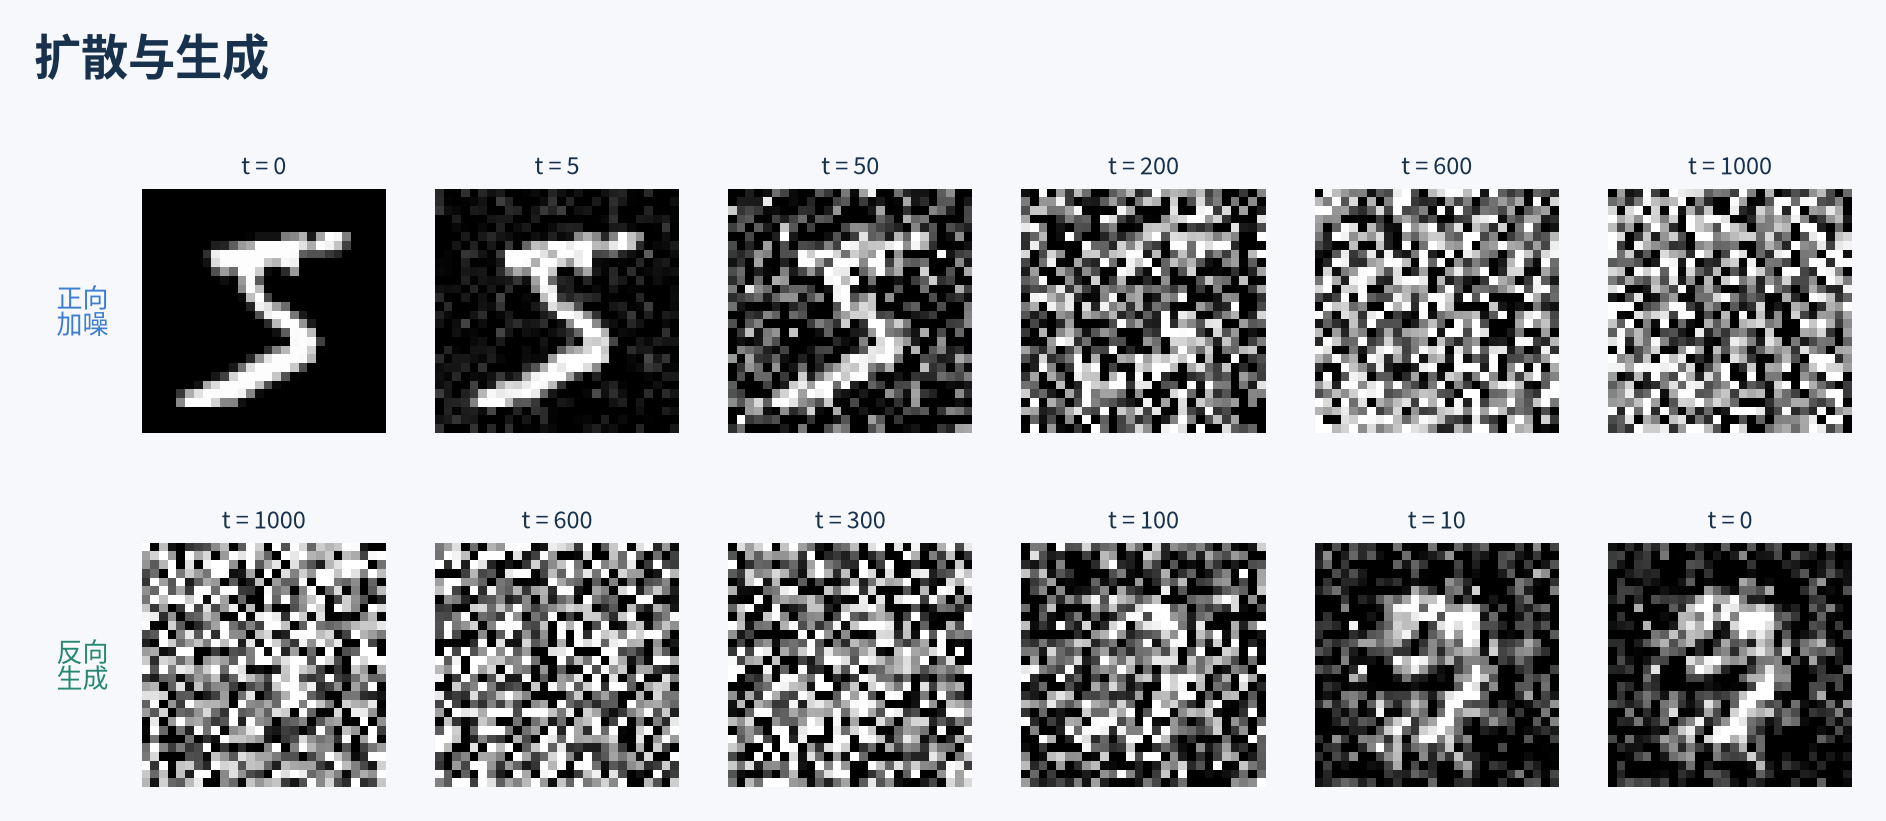

图的上排是一张训练图片的加噪过程；下排是模型从另一份噪声生成的轨迹。每次反向转移只处理当前状态和时间。对于足够小的步长，可以用高斯分布近似这种转移，并用神经网络确定其参数。模型是否能生成清楚的数字，取决于这些近似转移是否学得准确。

用 $q_0(x)$ 表示数据分布，$p_\theta(x)$ 表示模型生成的分布，其中 $\theta$ 是网络的权重和偏置，训练目标是使二者接近。每张 $28\times28$ 灰度图都可视作一个 784 维向量；本章不使用数字类别标签。

本实验使用 Python 3.12 和 PyTorch 2.14。读取 MNIST，并将像素缩放到 $[-1,1]$：


In [ ]:
import math
from pathlib import Path
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt

torch.manual_seed(13)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
data = datasets.MNIST("data", train=True, download=True, transform=transform)
train, val = random_split(data, [55000, 5000], generator=torch.Generator().manual_seed(0))
loader = DataLoader(train, batch_size=256, shuffle=True)
val_x = torch.stack([val[i][0] for i in range(512)]).to(device)


### 1.2 正向扩散过程

设 $x_0$ 为原图，$x_t$ 为第 $t$ 步的状态。正向扩散采用如下高斯转移：

$$
q(x_t\mid x_{t-1})
=\mathcal N\!\left(\sqrt{1-\beta_t}\,x_{t-1},\beta_t I\right).
$$

> 这里等价于每个点独立加高斯噪音，$\mathcal{N}$ 是高斯分布，第二个参数位是协方差矩阵

它对应一次简单的计算：

$$
x_t=\sqrt{1-\beta_t}\,x_{t-1}+\sqrt{\beta_t}\,z_t,
\qquad z_t\sim\mathcal N(0,I).
$$

$\beta_t$ 决定这一小步加入多少噪声；系数 $\sqrt{1-\beta_t}$ 同时削弱旧信号。若 $x_{t-1}$ 已服从标准高斯分布，这次转移仍得到标准高斯，因此噪声分布可以作为过程的稳定终点。

记 $\alpha_t=1-\beta_t$，$\bar\alpha_t=\prod_{s=1}^t\alpha_s$。把前一步代入后一步，利用独立高斯噪声的方差相加，可得：

$$
q(x_t\mid x_0)
=\mathcal N\!\left(\sqrt{\bar\alpha_t}\,x_0,
                   (1-\bar\alpha_t)I\right).
$$

例如，展开到第二步时，原图系数是 $\sqrt{\alpha_1\alpha_2}$，噪声方差为
$\alpha_2(1-\alpha_1)+(1-\alpha_2)=1-\alpha_1\alpha_2$；
重复展开便得到上式。因此，训练时可以直接从原图构造任意时间步的状态：

$$
x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,
\qquad \epsilon\sim\mathcal N(0,I).
$$

以下固定 $T=1000$、$\beta_t=0.01$。此时 $\bar\alpha_T=0.99^{1000}\approx4.3\times10^{-5}$，终点几乎不再包含原图信号。


In [ ]:
T = 1000
beta = torch.full((T + 1,), 0.01, device=device)
beta[0] = 0
alpha = 1 - beta
abar = torch.cumprod(alpha, dim=0)
mean_schedule = dict(beta=beta, alpha=alpha, abar=abar)

def at(values, t):
    return values[t].reshape(-1, 1, 1, 1)

def add_noise(x0, t, schedule, generator=None):
    eps = torch.randn(x0.shape, device=x0.device, generator=generator)
    a = at(schedule['abar'], t)
    return a.sqrt() * x0 + (1 - a).sqrt() * eps

times = torch.tensor([0, 100, 300, 600, 1000], device=device)
x0 = data[0][0].unsqueeze(0).expand(len(times), -1, -1, -1).to(device)
xt = add_noise(x0, times, mean_schedule, torch.Generator(device=device).manual_seed(7))
fig, axes = plt.subplots(1, len(times), figsize=(10, 2))
for image, t, ax in zip(xt, times, axes):
    ax.imshow(image[0].cpu(), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"t={t.item()}")
    ax.axis("off")
plt.show()


<code>t</code> 为每张图片指定噪声程度；<code>at</code> 将系数整理成 <code>[B,1,1,1]</code>，以便与图片相乘。正向过程由这些固定公式定义，不包含需要训练的网络。


### 1.3 反向生成模型

生成从 $x_T\sim\mathcal N(0,I)$ 开始，再依次采样 $x_{T-1},\ldots,x_0$。整条链的联合分布为：

$$
p_\theta(x_{0:T})
=p(x_T)\prod_{t=1}^T p_\theta(x_{t-1}\mid x_t).
$$

正向转移已知，并不意味着可以直接写出反向转移。给定一张带噪图，可能有许多较早状态产生它；这些状态的相对可能性还取决于数据分布，需要从训练图片中学习。

用 $\mu_\theta(x_t,t)$ 表示模型根据当前图像 $x_t$ 和时间 $t$ 预测的下一步状态 $x_{t-1}$ 的条件均值。它与图像同形状，每个位置表示对应像素的预测均值。以它为均值、$\beta_t I$ 为协方差，定义反向转移：

$$
p_\theta(x_{t-1}\mid x_t)
=\mathcal N\!\left(\mu_\theta(x_t,t),\beta_t I\right).
$$

均值决定下一步的中心位置，方差决定随机变化的幅度。均值依赖整张输入图，因此最终生成图片的像素可以形成相关的笔画结构。

本节的三层 MLP 输入展平的带噪图像与时间 $t$ 的 sin/cos 编码，输出 784 个数。将这些数还原为 $28\times28$ 的修正图，记为 $r_\theta(x_t,t)$。

当当前分布为标准高斯时，反向均值已知为 $\sqrt{\alpha_t}x_t$。模型将 MLP 的修正量与这个基准组合，得到最终预测的均值：

$$
\mu_\theta(x_t,t)
=\sqrt{\alpha_t}\,x_t+\sqrt{\beta_t}\,r_\theta(x_t,t).
$$

代码中，<code>self.net</code> 计算修正量 <code>r</code>，<code>MeanNetwork.forward()</code> 返回组合后的均值 $\mu_\theta$。



In [ ]:
class MeanNetwork(nn.Module):
    def __init__(self, beta):
        super().__init__()
        self.register_buffer('beta', beta.clone())
        self.register_buffer('alpha', 1 - beta)
        self.register_buffer('freq', torch.exp(-math.log(10000) * torch.arange(16) / 15))
        self.net = nn.Sequential(
            nn.Linear(784 + 32, 1024), nn.SiLU(),
            nn.Linear(1024, 1024), nn.SiLU(), nn.Linear(1024, 784))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, xt, t):
        phase = t.float()[:, None] * self.freq[None]
        time = torch.cat([phase.sin(), phase.cos()], dim=1)
        r = self.net(torch.cat([xt.flatten(1), time], dim=1)).reshape_as(xt)
        return at(self.alpha, t).sqrt() * xt + at(self.beta, t).sqrt() * r

mean_model = MeanNetwork(beta).to(device)


这一实现固定了 noise schedule 和反向方差，用来说明 2015 年框架中的学习与生成过程；原论文还研究了这些量的学习。[原论文与补充材料](https://proceedings.mlr.press/v37/sohl-dickstein15-supp.pdf)


### 1.4 训练目标

先固定一张训练图片 $x_0$。目标是提高模型赋予它的概率密度 $p_\theta(x_0)$，即最小化 $-\log p_\theta(x_0)$。

#### 1.4.1 从似然到可计算的上界

记 $x_{1:T}=(x_1,\ldots,x_T)$ 为全部中间状态，$x_{0:T}=(x_0,x_1,\ldots,x_T)$ 为包含原图的完整路径。模型定义了路径的联合概率密度，因此：

$$
p_\theta(x_0)
=\int p_\theta(x_{0:T})\,dx_{1:T}.
$$

这个积分包含所有可能的中间路径，直接计算很困难。正向过程 $q(x_{1:T}\mid x_0)$ 已知，可以将积分改写成对它取平均：

$$
p_\theta(x_0)
=\mathbb E_{q(x_{1:T}\mid x_0)}
\left[\frac{p_\theta(x_{0:T})}
{q(x_{1:T}\mid x_0)}\right].
$$

$\mathbb E$ 表示期望；下标指定按哪个分布取平均。这里相当于固定原图，反复运行正向加噪过程，对得到的路径计算括号中的值并取平均。以下将这个期望简写为 $\mathbb E_q$。

由于 $-\log$ 是凸函数，Jensen 不等式给出：

$$
-\log p_\theta(x_0)
=-\log\mathbb E_q
\left[\frac{p_\theta(x_{0:T})}{q(x_{1:T}\mid x_0)}\right]
\le
\mathbb E_q
\left[\log\frac{q(x_{1:T}\mid x_0)}{p_\theta(x_{0:T})}\right].
$$

将右侧记为 $\mathcal L_\theta(x_0)$。它是负对数似然的上界；取负号后，便是对数似然的变分下界。我们用这个可计算的上界作为训练目标。

#### 1.4.2 展开路径概率

先用两步链看清这个概率比值。此时原图是 $x_0$，两个中间状态是 $x_1,x_2$。正向路径概率可以按条件概率的乘法规则，换一种顺序写：

$$
q(x_1,x_2\mid x_0)
=q(x_2\mid x_0)\,q(x_1\mid x_2,x_0).
$$

模型的生成顺序则是 $x_2\to x_1\to x_0$：

$$
p_\theta(x_0,x_1,x_2)
=p(x_2)\,p_\theta(x_1\mid x_2)\,p_\theta(x_0\mid x_1).
$$

所以，上界中的比值变成：

$$
\frac{q(x_1,x_2\mid x_0)}
{p_\theta(x_0,x_1,x_2)}
=
\frac{q(x_2\mid x_0)}{p(x_2)}
\cdot
\frac{q(x_1\mid x_2,x_0)}{p_\theta(x_1\mid x_2)}
\cdot
\frac{1}{p_\theta(x_0\mid x_1)}.
$$

三类项已经出现在这里：终点分布的比值、中间反向转移的比值，以及最后生成原图的概率。正向路径以 $x_0$ 为已知条件，没有“生成 $x_0$”这一项；模型路径有，所以最后留下一个倒数。

取对数，将乘积变成和：

$$
\log\frac{q(x_1,x_2\mid x_0)}{p_\theta(x_0,x_1,x_2)}
=
\log\frac{q(x_2\mid x_0)}{p(x_2)}
+
\log\frac{q(x_1\mid x_2,x_0)}{p_\theta(x_1\mid x_2)}
-
\log p_\theta(x_0\mid x_1).
$$

对于一般的 $T$ 步正向链，利用马尔可夫性质，同样可以从右向左分解：

$$
q(x_{1:T}\mid x_0)
=q(x_T\mid x_0)
\prod_{t=2}^{T}q(x_{t-1}\mid x_t,x_0).
$$

这是对同一条已知正向路径概率的改写，不是把它换成了需要学习的反向模型。代入模型路径，再取对数和期望，得到：

$$
\begin{aligned}
\mathcal L_\theta(x_0)
={}&\mathbb E_q\log\frac{q(x_T\mid x_0)}{p(x_T)}\\
&+\sum_{t=2}^{T}\mathbb E_q
\log\frac{q(x_{t-1}\mid x_t,x_0)}
{p_\theta(x_{t-1}\mid x_t)}\\
&-\mathbb E_q\log p_\theta(x_0\mid x_1).
\end{aligned}
$$

到这里，只用了路径概率的分解，以及“乘积的对数等于对数的和”。

#### 1.4.3 将平均对数比写成 KL 散度

对于两个概率密度 $a(z)$、$b(z)$，KL 散度定义为：

$$
D_{\mathrm{KL}}(a\|b)
=\int a(z)\log\frac{a(z)}{b(z)}\,dz
=\mathbb E_{z\sim a}\left[\log\frac{a(z)}{b(z)}\right].
$$

它衡量用 $b$ 近似 $a$ 的差异；两者相同时为零。双竖线用于分隔两个分布，与条件概率中的单竖线含义不同。前面的损失已经出现了这种“按分子分布取平均的对数比”，因此可以识别为 KL 项。

**终点项。** 第一项只依赖 $x_T$，按它的分布 $q(x_T\mid x_0)$ 取平均：

$$
L_{\mathrm{prior}}
=D_{\mathrm{KL}}\bigl(q(x_T\mid x_0)\|p(x_T)\bigr).
$$

它比较加噪终点与生成所用的高斯先验。本章的 noise schedule 和先验都固定，因此这一项不依赖网络参数。

**反向转移项。** 对某个 $t$，先固定 $x_t$，对 $x_{t-1}$ 取平均。内层的平均对数比成为 KL；再对可能出现的 $x_t$ 取平均：

$$
L_{\mathrm{step},t}
=
\mathbb E_{q(x_t\mid x_0)}
\left[
D_{\mathrm{KL}}\left(
q(x_{t-1}\mid x_t,x_0)
\|p_\theta(x_{t-1}\mid x_t)
\right)
\right].
$$

这里比较的是训练时可计算的后验与模型预测的反向分布。外层期望保留，是因为同一张原图也会产生不同的带噪状态 $x_t$。

**重建项。** 最后一项没有概率比值，直接是模型生成原图的负对数似然：

$$
L_{\mathrm{recon}}
=-\mathbb E_{q(x_1\mid x_0)}
\log p_\theta(x_0\mid x_1).
$$

于是，用刚定义的三个名称，训练上界可写成：

$$
\mathcal L_\theta(x_0)
=L_{\mathrm{prior}}
+\sum_{t=2}^{T}L_{\mathrm{step},t}
+L_{\mathrm{recon}}.
$$

这三部分是原概率比值的分解结果，并非额外添加的三种损失。训练整个数据集时，还要对训练图片 $x_0$ 取平均。

#### 1.4.4 高斯反向转移的损失

**训练监督来自已知原图。** 给定 $x_0$ 后，由两个高斯分布的乘积：

$$
q(x_{t-1}\mid x_t,x_0)
\propto q(x_t\mid x_{t-1})q(x_{t-1}\mid x_0),
$$

可求得 $t\ge2$ 时的后验均值：

$$
\widetilde\mu_t(x_t,x_0)
=
\frac{\sqrt{\bar\alpha_{t-1}}\beta_t}{1-\bar\alpha_t}x_0+
\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t.
$$

模型的高斯负对数密度包含平方误差 $\|x_{t-1}-\mu_\theta(x_t,t)\|^2/(2\beta_t)$。在后验分布下取平均，这个平方误差分解为“后验各维方差之和”与“两个均值之差的平方”；前者不依赖网络参数。因此，高斯 KL 中与参数有关的部分为：

$$
\ell_t(\theta)
=\frac{1}{2\beta_t}
\left\|\widetilde\mu_t(x_t,x_0)-\mu_\theta(x_t,t)\right\|^2.
$$

这给出了一个可计算的监督任务：网络从 $x_t,t$ 预测反向均值，目标均值则由训练图片 $x_0$ 和正向过程算出。推理时没有 $x_0$，因此必须使用学到的网络。

$t=1$ 单独使用重建项。取 $p_\theta(x_0\mid x_1)=\mathcal N(\mu_\theta(x_1,1),\beta_1 I)$，其负对数似然中与参数有关的部分为
$\|x_0-\mu_\theta(x_1,1)\|^2/(2\beta_1)$。
因此，该步直接以原图为均值监督；不用对退化的零方差后验计算 KL。这里将像素视作连续向量，采用高斯重建项；原论文的端点处理见附录 B.2。[补充材料](https://proceedings.mlr.press/v37/sohl-dickstein15-supp.pdf)


In [ ]:
c0, ct = torch.zeros_like(beta), torch.zeros_like(beta)
c0[1:] = beta[1:] * abar[:-1].sqrt() / (1 - abar[1:])
ct[1:] = alpha[1:].sqrt() * (1 - abar[:-1]) / (1 - abar[1:])
c0[1], ct[1] = 1, 0
mean_schedule.update(c0=c0, ct=ct)

def mean_loss(model, x0, schedule, generator=None):
    T = len(schedule['beta']) - 1
    t = torch.randint(1, T + 1, (len(x0),), device=x0.device, generator=generator)
    xt = add_noise(x0, t, schedule, generator)
    target = at(schedule['c0'], t) * x0 + at(schedule['ct'], t) * xt
    pred = model(xt, t)
    return ((pred - target).square() / (2 * at(schedule['beta'], t))).mean()


代码均匀抽取时间步，并对像素取平均，保留了方差权重。返回值是去掉常数并归一化后的训练目标，不是完整的图像负对数似然。


### 1.5 模型训练

每次更新从训练集取图片，抽取时间步并加噪，计算后验均值目标，再更新网络。由于损失是各时间步之和的期望，一次更新只需抽取时间步，无需对整条生成链反向传播。


In [ ]:
EPOCHS = 60
optimizer = torch.optim.Adam(mean_model.parameters(), lr=5e-4)
history = []
for epoch in range(1, EPOCHS + 1):
    if epoch == 21:
        optimizer = torch.optim.Adam(mean_model.parameters(), lr=2e-4)
    mean_model.train()
    total, count = 0.0, 0
    for x0, _ in loader:
        x0 = x0.to(device)
        loss = mean_loss(mean_model, x0, mean_schedule)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(x0)
        count += len(x0)
    mean_model.eval()
    with torch.no_grad():
        val_loss = mean_loss(mean_model, val_x, mean_schedule,
                            torch.Generator(device=device).manual_seed(99)).item()
    history.append((total / count, val_loss))
    print(f"epoch={epoch}, train={history[-1][0]:.5f}, val={val_loss:.5f}")

mean_out = Path("mnist-mean-output")
mean_out.mkdir(exist_ok=True)
torch.save({"model": mean_model.state_dict(), "T": T, "prediction_type": "mean"},
           mean_out / "model.pt")
plt.plot([r[0] for r in history], label="train")
plt.plot([r[1] for r in history], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Mean loss"); plt.legend(); plt.show()


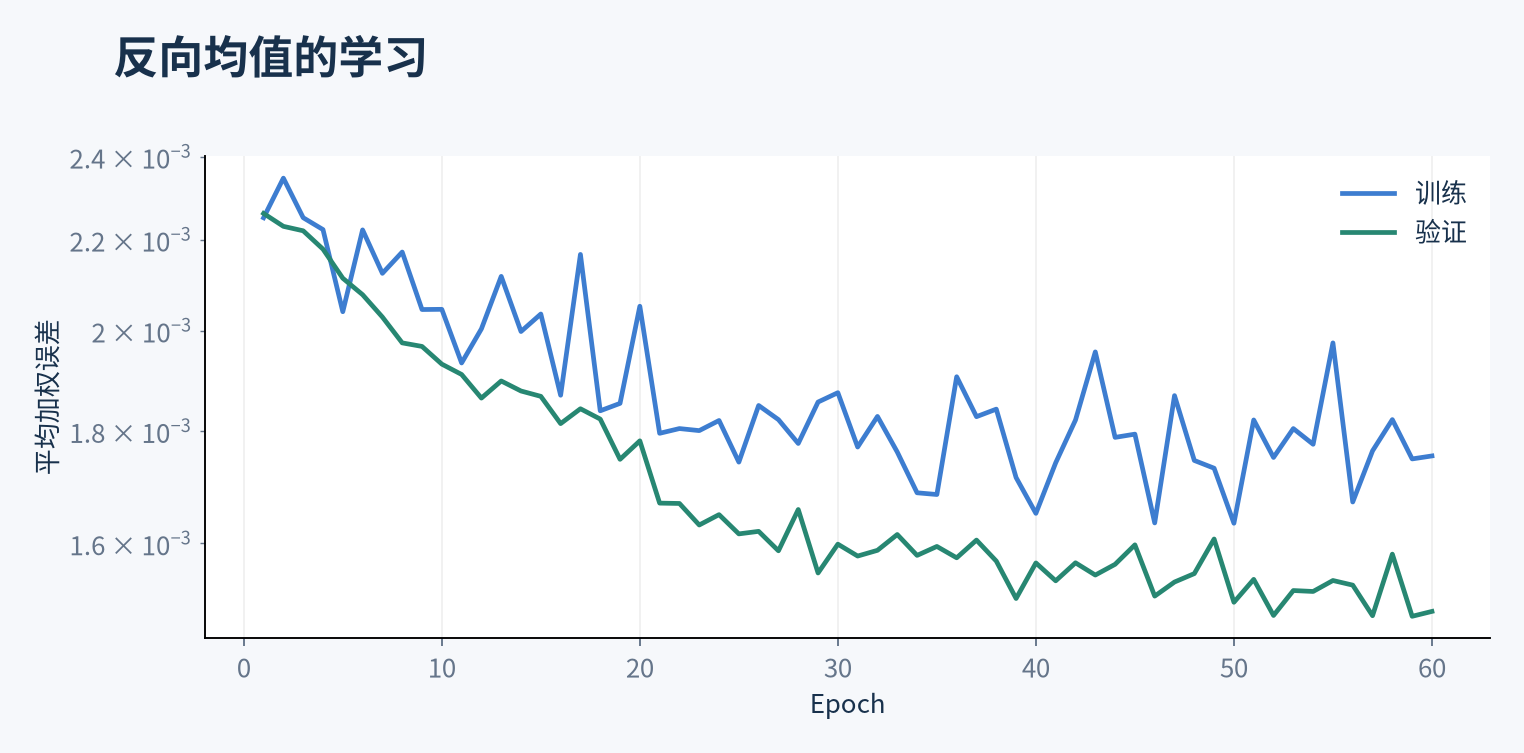

训练损失反映模型对局部反向转移的拟合。生成需要连续使用许多次这种转移，因此还要观察完整链产生的样本。


### 1.6 图像采样

训练完成后固定参数，从新噪声出发，重复：

$$
x_{t-1}=\mu_\theta(x_t,t)+\sqrt{\beta_t}\,z_t,
\qquad z_t\sim\mathcal N(0,I).
$$

这里每一步都使用网络输出的均值，并按定义好的方差采样。最后一步也包含随机项，与本章采用的正方差重建分布一致。


In [ ]:
@torch.no_grad()
def sample_mean(model, schedule, initial_noise, seed=7):
    x = initial_noise.clone()
    T = len(schedule['beta']) - 1
    rng = torch.Generator(device=x.device).manual_seed(seed)
    states = {T: x.clone()}
    for step in range(T, 0, -1):
        t = torch.full((len(x),), step, dtype=torch.long, device=x.device)
        z = torch.randn(x.shape, device=x.device, generator=rng)
        x = model(x, t) + schedule['beta'][step].sqrt() * z
        if step - 1 in {600, 300, 100, 10, 0}:
            states[step - 1] = x.clone()
    return x, states

mean_model.eval()
fixed = torch.randn(16, 1, 28, 28, device=device,
                    generator=torch.Generator(device=device).manual_seed(314))
samples, states = sample_mean(mean_model, mean_schedule, fixed)
grid = make_grid((samples.cpu().clamp(-1, 1) + 1) / 2, nrow=4)
plt.figure(figsize=(5, 5))
plt.imshow(grid.permute(1, 2, 0)); plt.axis("off"); plt.show()


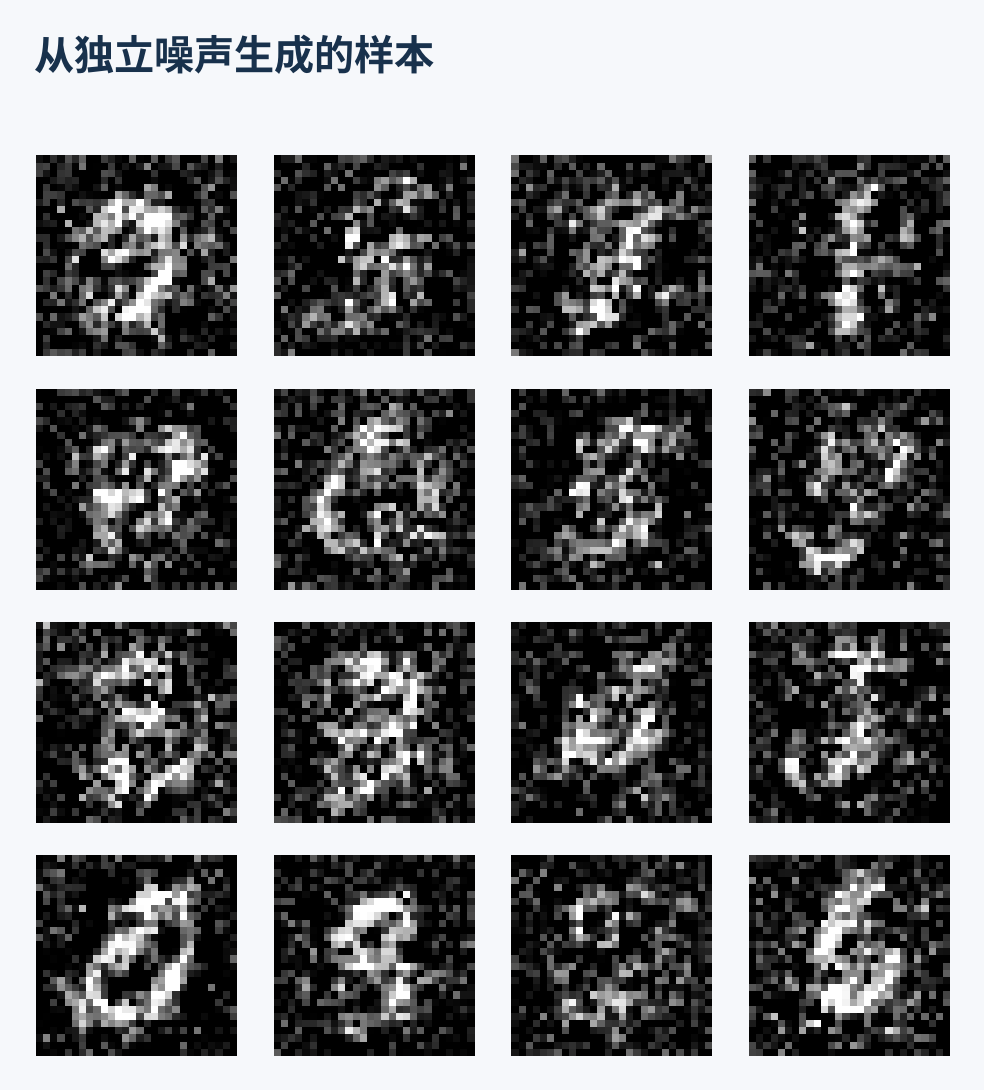

经过训练，部分样本已经形成数字轮廓，但仍有噪点和变形。局部转移的预测误差会在长链中积累；损失下降与完整生成质量需要结合观察。


### 1.7 小结

- 正向过程把数据逐步变成简单分布，并提供训练样本。
- 反向模型由许多可计算的条件转移组成，从噪声逐步生成图像。
- 已知训练原图时可以计算后验；它为反向模型提供监督。
- 本章学习反向均值。下一章 DDPM 将在同一框架下引入噪声预测参数化，并改变训练时各噪声程度的权重。


### 1.8 练习

1. 将扩散步数减少到 100，保持 $\beta_t=0.01$，计算终点的信号保留量。此时直接从标准高斯开始生成，哪项建模假设变弱了？
2. 固定初始噪声，分别保留和移除反向过程的随机项。观察输出，并说明后者是否还在采样本章定义的高斯转移。
3. 在训练时把真实原图也输入网络，会怎样改变训练任务？为什么这样的网络不能按本章方法从新噪声独立生成？


## 2．去噪扩散概率模型（DDPM）

2020 年，Ho 等人提出 DDPM，沿用逐步加噪与反向生成的框架，重新组织反向均值的参数化和训练目标。论文在无条件 CIFAR-10 上报告 FID 3.17，展示了这种设计用于高质量图像生成的效果。[DDPM](https://arxiv.org/abs/2006.11239)

第一章直接学习反向均值。本章改为预测正向过程中加入的噪声，再由噪声预测计算反向均值。


### 2.1 噪声预测参数化

由正向过程：

$$
x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,
$$

可以把干净数据写成：

$$
x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon}{\sqrt{\bar\alpha_t}}.
$$

将它代入第一章的后验均值公式：

$$
\widetilde\mu_t(x_t,x_0)
=\frac1{\sqrt{\alpha_t}}
\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon\right).
$$

因此，可以用网络预测噪声 $\epsilon_\theta(x_t,t)$，并据此定义模型均值：

$$
\mu_\theta(x_t,t)
=\frac1{\sqrt{\alpha_t}}
\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}
\epsilon_\theta(x_t,t)\right).
$$

网络输出的含义发生了变化，但采样依然使用反向条件分布。预测噪声与直接预测均值，是对同一反向均值函数的不同参数化。


### 2.2 简化训练目标

若模型的逆步方差固定为 $\sigma_t^2I$，将噪声参数化代入高斯 KL，中间步骤的参数相关项为：

$$
L_{t-1}
=\mathbb E\left[
\frac{\beta_t^2}{2\sigma_t^2\alpha_t(1-\bar\alpha_t)}
\|\epsilon-\epsilon_\theta(x_t,t)\|^2
\right]+C,\qquad t\ge2.
$$

即使第一章取常数 $\beta_t$，转换成噪声误差后，这个权重也随 $\bar\alpha_t$ 变化。DDPM 使用的简化目标省去该权重：

$$
\mathcal L_{\mathrm{simple}}
=\mathbb E_{x_0,t,\epsilon}
\|\epsilon-\epsilon_\theta(x_t,t)\|^2.
$$

这改变了不同噪声程度对训练的相对影响，不是完整变分目标的逐项恒等式。原论文通过实验比较了这些选择，而不是仅凭代数等价就断言它们具有相同生成效果。


### 2.3 噪声预测网络

以下实现复用第一章的 MNIST 数据和固定的 noise schedule，另行训练噪声预测器。采用一个小型时间条件 U-Net，输入与输出都是 <code>[B,1,28,28]</code>。时间告诉网络当前的噪声程度，下采样和跳跃连接组织不同尺度的图像特征。

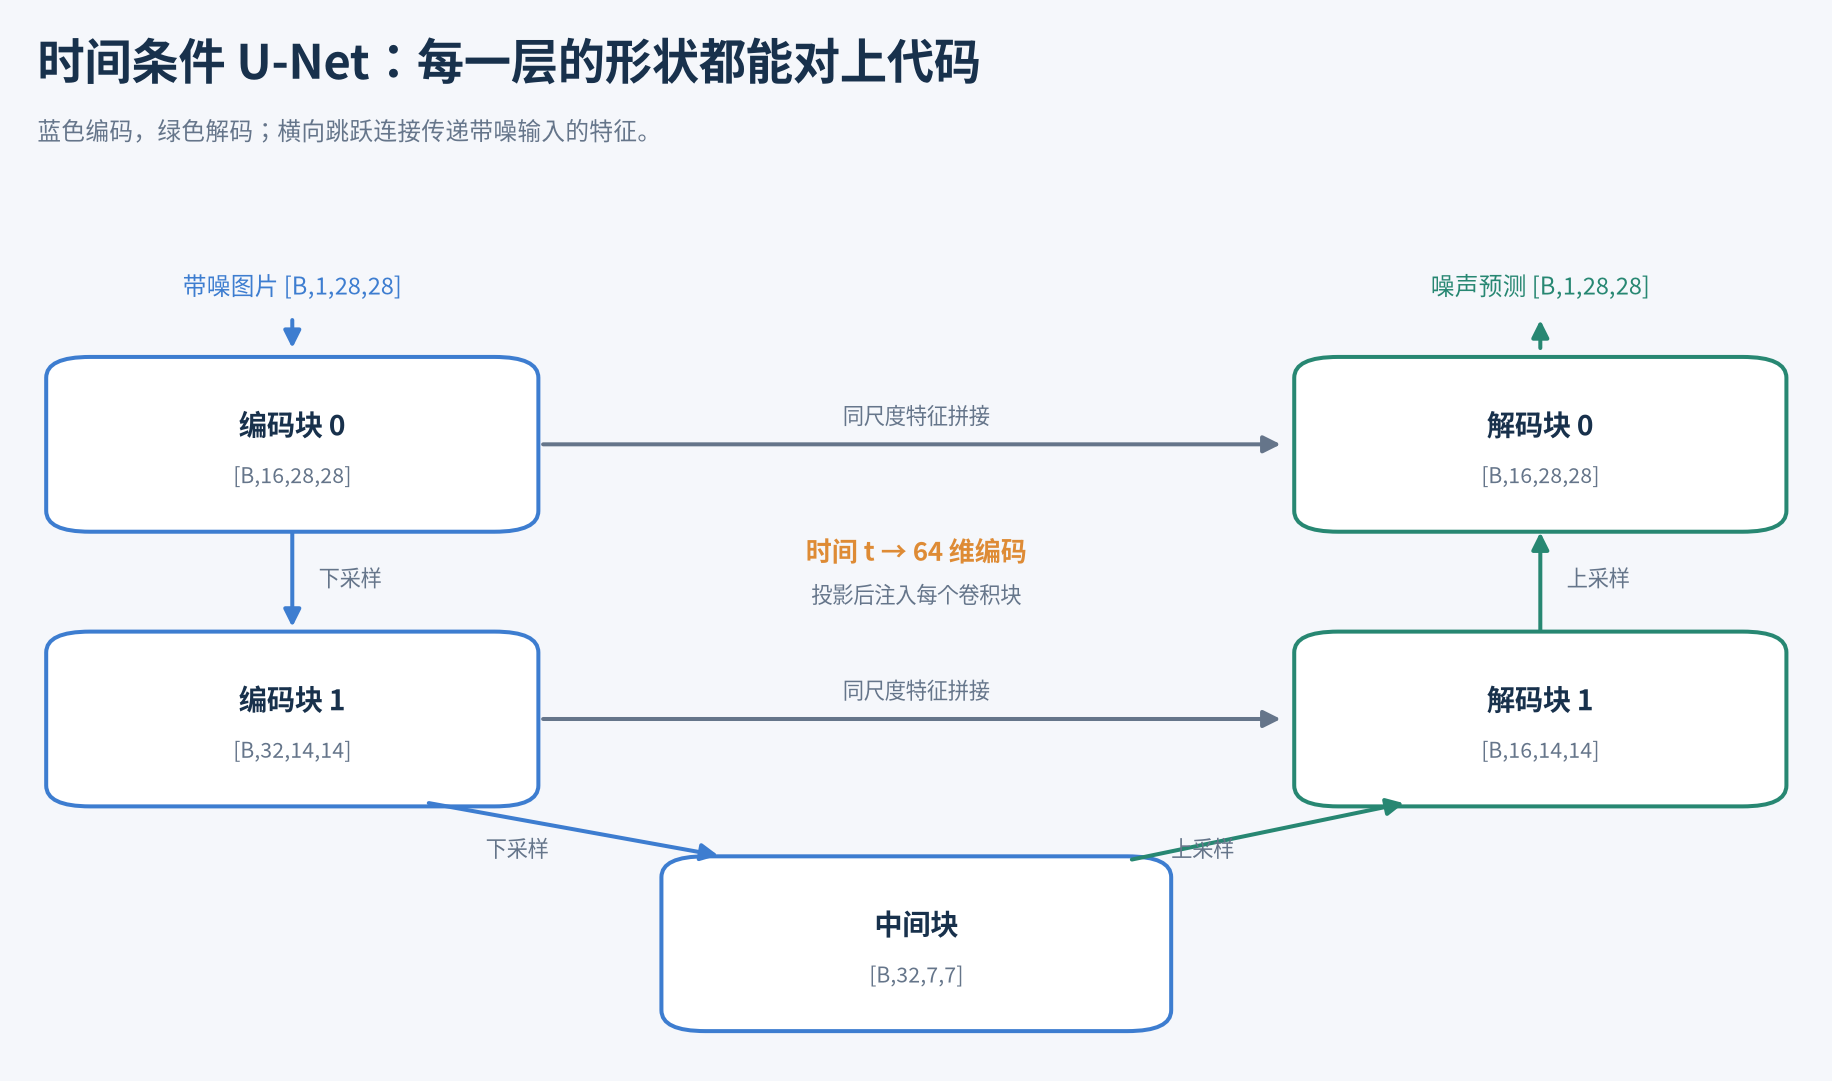


In [ ]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        freq = torch.exp(-math.log(10000) * torch.arange(dim // 2) / (dim // 2 - 1))
        self.register_buffer("freq", freq)

    def forward(self, t):
        phase = t.float()[:, None] * self.freq[None, :]
        return torch.cat([phase.sin(), phase.cos()], dim=1)

class Block(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, padding=1)
        self.time = nn.Linear(64, cout)
        self.body = nn.Sequential(nn.GroupNorm(4, cout), nn.SiLU(),
                                  nn.Conv2d(cout, cout, 3, padding=1))
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, emb):
        h = self.conv(x) + self.time(emb)[:, :, None, None]
        return self.skip(x) + self.body(h)

class TinyUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.time = nn.Sequential(TimeEmbedding(), nn.Linear(64, 64), nn.SiLU())
        self.enc0, self.enc1 = Block(1, 16), Block(16, 32)
        self.down0 = nn.Conv2d(16, 16, 4, stride=2, padding=1)
        self.down1 = nn.Conv2d(32, 32, 4, stride=2, padding=1)
        self.mid, self.dec1, self.dec0 = Block(32, 32), Block(64, 16), Block(32, 16)
        self.out = nn.Conv2d(16, 1, 3, padding=1)

    def condition(self, t, labels=None):
        return self.time(t)  # 基础实验只使用时间条件。

    def forward(self, x, t, labels=None):
        emb = self.condition(t, labels)
        h0 = self.enc0(x, emb)                         # [B,16,28,28]
        h1 = self.enc1(self.down0(h0), emb)             # [B,32,14,14]
        h = self.mid(self.down1(h1), emb)               # [B,32,7,7]
        h = F.interpolate(h, size=h1.shape[-2:], mode="nearest")
        h = self.dec1(torch.cat([h, h1], dim=1), emb)
        h = F.interpolate(h, size=h0.shape[-2:], mode="nearest")
        return self.out(self.dec0(torch.cat([h, h0], dim=1), emb))


训练时，噪声 $\epsilon$ 是代码刚刚采样的已知量，因此可以直接作为监督目标：


In [ ]:
def make_schedule(T, device):
    beta = torch.full((T + 1,), 0.01, device=device)
    beta[0] = 0
    alpha = 1 - beta
    return beta, alpha, torch.cumprod(alpha, dim=0)

def extract(values, t):
    return values[t].reshape(-1, 1, 1, 1)

def noise_loss(model, x0, abar, generator=None):
    t = torch.randint(1, len(abar), (len(x0),), device=x0.device, generator=generator)
    eps = torch.randn(x0.shape, device=x0.device, generator=generator)
    a = extract(abar, t)
    xt = a.sqrt() * x0 + (1 - a).sqrt() * eps
    return F.mse_loss(model(xt, t), eps)


第一章的模型输出反向均值，这里的模型输出噪声。它们使用不同的 checkpoint，后面的 DDIM 和 CFG 实验使用本章的噪声预测模型。


In [ ]:
torch.manual_seed(0)
model = TinyUNet().to(device)
schedule = make_schedule(T=1000, device=device)
opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=0)
DDPM_EPOCHS = 10
for epoch in range(1, DDPM_EPOCHS + 1):
    model.train()
    total, count = 0.0, 0
    for x0, _ in loader:
        x0 = x0.to(device)
        loss = noise_loss(model, x0, schedule[2])
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        total += loss.item() * len(x0)
        count += len(x0)
    print(f"epoch={epoch}, noise_mse={total/count:.4f}")
model.eval()
out = Path("mnist-ddpm-output")
out.mkdir(exist_ok=True)
torch.save({"model": model.state_dict(), "T": 1000, "prediction_type": "epsilon"},
           out / "model.pt")


### 2.4 DDPM 采样

从新噪声开始，在每个时间步预测 $\epsilon$，据此估计干净图像和反向均值。下面选择后验方差
$\widetilde\beta_t=\beta_t(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)$；
最后一步不再加入噪声。这与第一章所有步骤采用正方差 $\beta_t$ 的设置不同。

代码还将干净图像估计裁剪到 MNIST 的 $[-1,1]$ 范围。该裁剪是采样实现中的选择，不属于高斯后验公式的推导。


In [ ]:
@torch.no_grad()
def sample_ddpm(model, schedule, initial_noise, seed=123):
    beta, alpha, abar = schedule
    x = initial_noise.clone()
    rng = torch.Generator(device=x.device).manual_seed(seed)
    frames = [x.clone()]
    T = len(beta) - 1
    for step in range(T, 0, -1):
        t = torch.full((len(x),), step, device=x.device, dtype=torch.long)
        eps = model(x, t)
        x0_hat = ((x - (1 - abar[step]).sqrt() * eps) / abar[step].sqrt()).clamp(-1, 1)
        denom = 1 - abar[step]
        c0 = beta[step] * abar[step - 1].sqrt() / denom
        ct = alpha[step].sqrt() * (1 - abar[step - 1]) / denom
        mean = c0 * x0_hat + ct * x
        var = beta[step] * (1 - abar[step - 1]) / denom
        z = torch.randn(x.shape, device=x.device, generator=rng) if step > 1 else 0
        x = mean + var.sqrt() * z
        if step - 1 in {T * 3 // 4, T // 2, T // 4, 0}:
            frames.append(x.clone())
    return x, frames

fixed = torch.randn(16, 1, 28, 28, device=device,
                    generator=torch.Generator(device=device).manual_seed(314))
samples, frames = sample_ddpm(model, schedule, fixed)
grid = make_grid((samples.cpu().clamp(-1, 1) + 1) / 2, nrow=4)
plt.figure(figsize=(5, 5))
plt.imshow(grid.permute(1, 2, 0)); plt.axis("off"); plt.show()


### 2.5 参数化、noise schedule 与骨干网络

DDPM 的噪声预测、训练损失的时间权重、noise schedule 和网络骨干是不同的选择。改变监督目标不要求同时更换骨干；本例使用 U-Net，是为了连接后续图像模型常用的结构，而不是把它当作噪声参数化的必要条件。

noise schedule 也可以独立改进。Improved DDPM 提出的 cosine noise schedule，用余弦曲线控制信号保留比例，并研究可学习的反向方差。本章为便于衔接，仍使用第一章的固定 noise schedule。[Improved DDPM](https://arxiv.org/abs/2102.09672)


## 3．Score 视角：网络到底估计了哪个分布的方向？

2019 年 NCSN 从另一角度处理生成问题：估计不同噪声尺度的数据分布的 score，再用这些方向进行采样。score 定义为对输入求梯度：

$$
s_t(x)=\nabla_x\log q_t(x).
$$

它指向局部对数密度增大的方向。多噪声尺度让学习目标覆盖从模糊整体结构到细致局部结构的范围。这与概率扩散是有不同起点、后来建立联系的路线。[NCSN](https://arxiv.org/abs/1907.05600)


### 3.1 预测噪声与估计 score 怎样联系？

对于一对 $(x_0,x_t)$，条件高斯的梯度容易求：

$$
\nabla_{x_t}\log q(x_t\mid x_0)
=-\frac{x_t-\sqrt{\bar\alpha_t}x_0}{1-\bar\alpha_t}
=-\frac{\epsilon}{\sqrt{1-\bar\alpha_t}}.
$$

但模型输入没有 $x_0$。平方损失的最优解是条件期望，所以网络学到的是 $\mathbb E[\epsilon\mid x_t,t]$，而不是每次都能识别某一训练样本唯一的原始噪声。对条件 score 做这个平均，得到边缘分布的 score：

$$
s_t(x_t)
=\mathbb E[\nabla_{x_t}\log q(x_t\mid x_0)\mid x_t]
\approx-\frac{\epsilon_\theta(x_t,t)}{\sqrt{1-\bar\alpha_t}}.
$$

第一式可由 $q_t(x_t)=\int q(x_t\mid x_0)p_{\mathrm{data}}(x_0)\,dx_0$ 求导得到。它说明训练对提供容易计算的监督，而网络通过大量样本学习分布层面的方向。


### 3.2 随机逆过程与确定性 ODE

Score SDE 将多种方法放到连续时间框架。若前向过程是
$dx=f(x,t)dt+g(t)dW_t$，
其逆时间 SDE 使用漂移 $f-g^2s_t$；对应的 probability-flow ODE 使用 $f-\tfrac12g^2s_t$，不含布朗噪声项。二者在生成时沿前向时间的反方向，从噪声走向数据。[Score SDE](https://arxiv.org/abs/2011.13456)

在精确 score 和相应条件下，这两种过程具有相同的时间边缘分布，但**同分布不等于同一条样本轨迹**。学到的 score 有误差，离散求解也有误差，因此不能由连续理论直接保证任意少步实现输出相同。这里给出概念桥梁；反向 SDE 定理本身不在本入门章节展开证明。


## 4．DDIM：改变采样过程，减少模型调用

DDPM 的高质量生成需要多次调用去噪网络。DDIM 的关键贡献是构造具有相同前向边缘和相同训练目标的一族过程，使已有 DDPM 噪声预测器可以用于不同采样轨迹，包括确定性和跳步采样。通常无需另训一套“DDIM 网络”。[DDIM](https://arxiv.org/abs/2010.02502)


### 4.1 先估计干净样本，再前往更早的噪声程度

从当前 $x_t$ 得到：

$$
\widehat x_0=
\frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta(x_t,t)}
{\sqrt{\bar\alpha_t}}.
$$

选择一个更早的时间 $r<t$，DDIM 更新可以写为：

$$
\sigma_{t\to r}
=\eta\sqrt{\frac{1-\bar\alpha_r}{1-\bar\alpha_t}}
\sqrt{1-\frac{\bar\alpha_t}{\bar\alpha_r}},
$$
$$
x_r=\sqrt{\bar\alpha_r}\widehat x_0+
\sqrt{1-\bar\alpha_r-\sigma_{t\to r}^2}\,
\epsilon_\theta(x_t,t)+\sigma_{t\to r}z.
$$

本节使用 $0\le\eta\le1$。$\eta=0$ 时没有每一步新增的随机项，给定初始噪声后轨迹确定；$\eta=1$ 配合相邻时间步，对应后验方差形式的 DDPM 更新。跳步时必须使用实际的 $r$，不能只减少循环次数却继续代入相邻 $t-1$ 的系数。

当 $r=0$ 时，$\bar\alpha_0=1$，公式返回 $\widehat x_0$。这也解释了代码为什么为干净端点保留索引 0。


### 4.2 使用 DDPM checkpoint 更换采样器

下面是确定性 DDIM。代码延续 MNIST 的 $\widehat x_0$ 裁剪，并在裁剪后重新计算与当前分解一致的噪声项；这是显式的实现选择，不将裁剪后的代码冒充论文的未经修改公式。代码单元复用前面导入的 `torch` 和模型定义：


In [ ]:
@torch.no_grad()
def sample_ddim(model, abar, initial_noise, steps=50):
    T = len(abar) - 1
    assert 1 <= steps <= T
    times = torch.linspace(T, 1, steps).round().long().tolist()
    x = initial_noise.clone()
    for t, prev in zip(times, times[1:] + [0]):
        ts = torch.full((len(x),), t, device=x.device, dtype=torch.long)
        eps = model(x, ts)
        x0 = ((x - (1 - abar[t]).sqrt() * eps) / abar[t].sqrt()).clamp(-1, 1)
        # 裁剪x0后重新求eps，使本步分解仍一致；不裁剪时这行等于原eps。
        eps = (x - abar[t].sqrt() * x0) / (1 - abar[t]).sqrt()
        x = abar[prev].sqrt() * x0 + (1 - abar[prev]).sqrt() * eps
    return x


加载同一个训练 checkpoint；这样只改变采样方法，模型参数仍然相同：


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt = torch.load("mnist-ddpm-output/model.pt", map_location=device, weights_only=True)
assert ckpt["prediction_type"] == "epsilon"
model = TinyUNet().to(device)
model.load_state_dict(ckpt["model"])
model.eval()
schedule = make_schedule(ckpt["T"], device)
xT = torch.randn(16, 1, 28, 28, device=device)
samples = sample_ddim(model, schedule[2], xT, steps=50)


在本例中，这把网络调用次数从 1000 次改为 50 次；它不保证端到端速度精确提高二十倍，也不保证质量不变。更少评估意味着更粗的路径近似。讨论“20 步模型”时，应先分清 training timesteps 的数量、推理评估数，以及是否使用了蒸馏模型。

后续数值求解器沿这个方向继续发展：利用生成 ODE 的结构、选择不同阶数和步长，以有限的模型评估获得更好的近似。求解器、时间点分布和预测参数化共同决定效果；只比较步数会遗漏这些条件。


## 5．Latent Diffusion 与 Stable Diffusion：控制内容并降低图像生成成本


### 5.1 从“生成某个数字”到“生成指定的数字”

基础实验只学习 $p(x)$。若想指定数字 $c=7$，模型需要学习条件分布 $p(x\mid c)$。最小改动是将类别 embedding 与时间 embedding 相加，然后仍让网络预测加入图像的噪声：

$$
\epsilon_\theta(x_t,t,c),\qquad
\mathcal L_c=\mathbb E\|\epsilon-\epsilon_\theta(x_t,t,c)\|^2.
$$

损失目标没有变成分类标签，标签只是控制生成内容的条件。对于文生图，条件换成文本编码器产生的表示；模型仍要根据当前带噪状态和时间生成所需预测。


### 5.2 Classifier-Free Guidance：把条件方向放大

Classifier-Free Guidance（CFG）在训练时以一定概率丢弃条件，使同一网络同时学有条件和无条件预测。采样时组合二者：

$$
\epsilon_{\mathrm{cfg}}
=\epsilon_u+s(\epsilon_c-\epsilon_u),
\quad
\epsilon_u=\epsilon_\theta(x_t,t,\varnothing),
\quad
\epsilon_c=\epsilon_\theta(x_t,t,c).
$$

$s=0$ 使用无条件预测，$s=1$ 是普通条件预测，$s>1$ 沿条件差异方向外推。原论文也使用 $(1+w)\epsilon_c-w\epsilon_u$ 的写法，对应 $s=1+w$。读实现时要先确认 scale 的约定。[CFG](https://arxiv.org/abs/2207.12598)

结合 score 关系，条件与无条件 score 的差异满足
$\nabla_x\log p_t(x\mid c)-\nabla_x\log p_t(x)=\nabla_x\log p_t(c\mid x)$，
因此放大差异会增强条件对生成方向的影响。较大 guidance 可以加强条件符合程度，也可能牺牲多样性、产生过强对比等失真；它不是越大越好的质量按钮。

下面给出第二章噪声预测网络的条件扩展。数字 0–9 各有一个 embedding，编号 10 是专门训练的空条件。代码单元复用前面的 `torch`、`nn`、`F`、`TinyUNet` 和 `extract`：


In [ ]:
class ConditionalUNet(TinyUNet):
    def __init__(self):
        super().__init__()
        self.label = nn.Embedding(11, 64)  # 0~9是类别，10表示无条件。

    def condition(self, t, labels=None):
        if labels is None:
            labels = torch.full_like(t, 10, dtype=torch.long)
        return self.time(t) + self.label(labels)

def cfg_loss(model, x0, labels, abar, drop_prob=0.1):
    t = torch.randint(1, len(abar), (len(x0),), device=x0.device)
    eps = torch.randn_like(x0)
    a = extract(abar, t)
    xt = a.sqrt() * x0 + (1 - a).sqrt() * eps
    dropped = torch.rand(len(x0), device=x0.device) < drop_prob
    condition = torch.where(dropped, 10, labels)
    return F.mse_loss(model(xt, t, condition), eps)

def cfg_predict(model, x, t, labels, scale=3.0):
    uncond = model(x, t, None)
    cond = model(x, t, labels)
    return uncond + scale * (cond - uncond)


接入第二章噪声预测训练循环时，需要创建新的 `ConditionalUNet` 和优化器，保留 DataLoader 返回的标签并将其转为同设备的 long Tensor，用 `cfg_loss(model,x0,labels,abar)` 替换原损失。验证也要明确测的是条件预测、无条件预测，还是带条件丢弃的目标。**第二章的无条件 DDPM checkpoint 不能直接获得没有训练过的类别控制能力。**

下面是可选实验，默认关闭以避免 Run All 意外再启动一轮完整训练。打开开关后会新建并训练条件模型，再让每张图的目标标签都为 7：


In [ ]:
RUN_CONDITIONAL = False
if RUN_CONDITIONAL:
    conditional = ConditionalUNet().to(device)
    optimizer = torch.optim.AdamW(conditional.parameters(), lr=2e-4, weight_decay=0)
    for _ in range(10):
        conditional.train()
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            loss = cfg_loss(conditional, images, labels, schedule[2])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
    conditional.eval()
    labels = torch.full((len(xT),), 7, dtype=torch.long, device=xT.device)
    predict = lambda x, t: cfg_predict(conditional, x, t, labels, scale=3.0)
    samples = sample_ddim(predict, schedule[2], xT, steps=50)
    save_image((samples.clamp(-1, 1) + 1) / 2, out / "conditional-7.png", nrow=4)


普通 CFG 每次更新需要条件/无条件两份预测，可以拼成一个更大的 batch，但这仍意味着更多模型计算。后面 FLUX 的 guidance distillation 又是另一个机制，不能只因接口参数也叫 guidance 就推断它执行同样的两次预测。


### 5.3 为什么到潜空间里生成？

从 $28\times28$ 灰度图增大到 $512\times512$ RGB，直接在像素空间做很多次大网络推理会显著增加计算和存储。Latent Diffusion 的思路是：先训练自编码器，把图片映射到较小的表示，再在这个表示上学习扩散；最后用解码器恢复图片。论文预印本发布于 2021 年 12 月，正式发表于 CVPR 2022。[LDM](https://arxiv.org/abs/2112.10752)

$$
x \xrightarrow{E} z_0,\qquad
z_t=\sqrt{\bar\alpha_t}z_0+\sqrt{1-\bar\alpha_t}\epsilon,\qquad
\widehat z_0\xrightarrow{D}\widehat x.
$$

自编码器先学习哪些信息需要保留；扩散模型再学习这些压缩表示的分布。压缩减小了空间计算，但也引入重建上限：如果自编码器丢掉了重要细节，下游生成并不能自动证明它们会恢复。VAE 的重建和正则化目标与扩散噪声损失是不同的训练任务。

需要注意术语：DDPM 也可被称为 latent-variable model，因为中间状态不可观测；LDM 这里强调的则是**自编码器产生的压缩表示空间**，两种 “latent” 不应仅凭相同单词混为一谈。


### 5.4 Stable Diffusion v1 把哪些组件组合起来？

Stable Diffusion v1 是 LDM 思路的具体文生图系统。其公开实现使用空间压缩因子 8、4 通道的自编码器 latent、U-Net 和冻结的 CLIP 文本编码器。以 $512\times512$ 图像为例：[官方实现](https://github.com/CompVis/stable-diffusion/blob/21f890f9da3cfbeaba8e2ac3c425ee9e998d5229/README.md) [配置](https://github.com/CompVis/stable-diffusion/blob/21f890f9da3cfbeaba8e2ac3c425ee9e998d5229/configs/stable-diffusion/v1-inference.yaml)

```text
训练图片 [B,3,512,512] → 自编码器 → latent [B,4,64,64]
                                                ↓ 加噪
prompt → CLIP 文本编码器 → 文本表示 ─────────→ U-Net(z_t,t,text)
                                                ↓ 噪声预测
                                           回归已知噪声

生成时：
prompt → 文本表示 ────────────────────────────────┐
高斯 latent [B,4,64,64] → 多步 U-Net + 采样器 ──> z_0
                                                ↓ VAE decoder
                                           RGB 图片
```

文本一般只需编码一次，去噪网络则反复运行，最后解码 latent。文生图推理没有一张待编码的原始目标图片；图中的图像 encoder 属于训练准备或图生图等输入路径。

U-Net 中的 cross-attention 以图像特征产生 query，以文本表示产生 key/value，让空间位置能利用相关文字信息。它与前面 MNIST 类别 embedding 的作用相同，都是条件信息进入模型的方式，但表达能力和数据组织更丰富。

在 Stable Diffusion v1 中还要按模型配置缩放 latent；其公开配置的缩放因子为 0.18215，不能将这个数当成所有后续模型的共同常量。$512^2$ 到 $64^2$ 意味着空间位置减少 64 倍，但这不推出端到端速度恰好提高 64 倍：通道数、网络结构、文本处理和 VAE 成本都还存在。

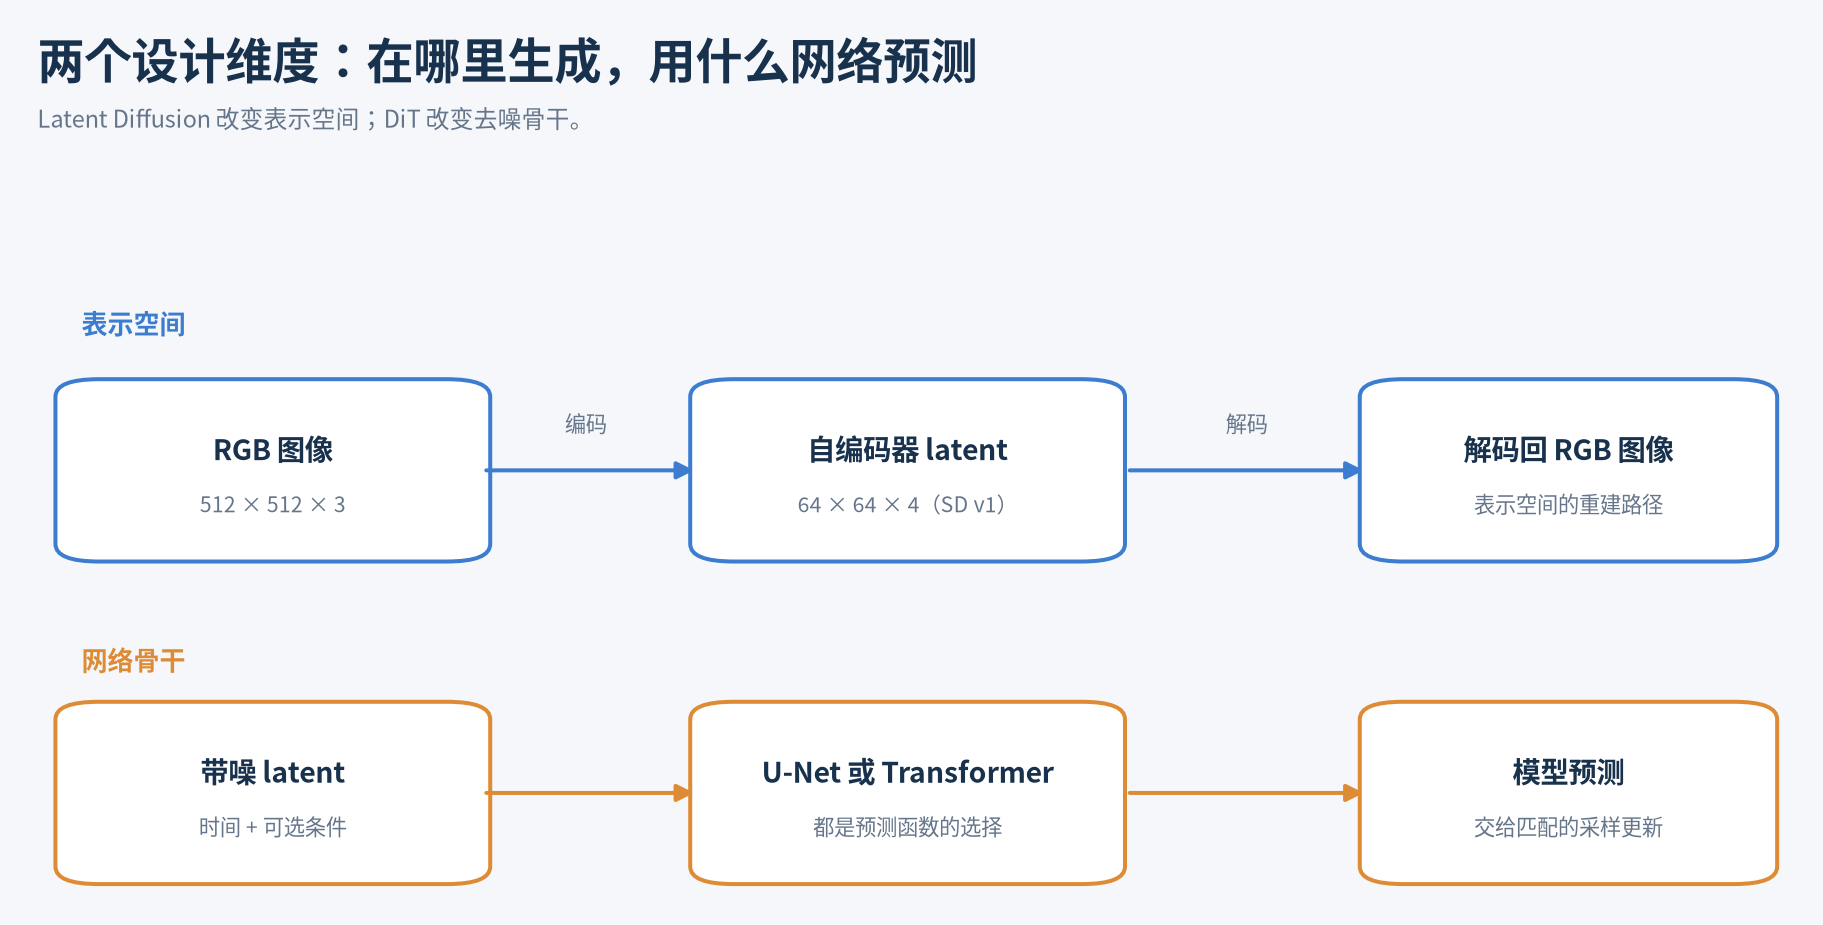

该阶段的主要成果，是将高分辨率条件生成放进一个更容易训练和部署的系统组合中；“换到 latent”“加入文本条件”和“换采样器”分别改变不同部分。


## 6．DiT：把去噪骨干换成可扩展的 Transformer

DiT 预印本发表于 2022 年 12 月，正式发表于 ICCV 2023。它在 latent diffusion 中用 Transformer 替换 U-Net，并系统研究模型计算规模与生成质量的关系。原始任务是**类别条件 ImageNet 生成**，不能把原始 DiT 直接描述成已经包含完整文生图系统。[DiT](https://arxiv.org/abs/2212.09748)


### 6.1 从 latent 到 token，再还原回预测

以原始 DiT 的 $256\times256$ 图像设定为例，因子 8 的自编码器产生 $32\times32\times4$ latent。若 latent patch 边长为 2，则每个 patch 有 $2\times2\times4=16$ 个数，共有 $16\times16=256$ 个 tokens。线性投影将每个 patch 映射到 Transformer 隐藏维度。

```text
带噪 latent → patchify / projection → 加入位置信息
                                         ↓
                timestep + class → 多个 DiT blocks
                                         ↓
                              预测每个 patch 的数值
                                         ↓
                             unpatchify 回空间布局
```

注意三个数字属于不同维度：VAE 压缩因子决定图像到 latent 的空间缩小；latent patch 大小决定 Transformer token 数；hidden size 决定每个 token 的特征宽度。它们不能只用一个“压缩比例”替代。


### 6.2 条件怎样进入 DiT block？

原始 DiT 探索多种条件注入方式，其中 adaLN-Zero 让时间和类别条件产生归一化的 shift、scale 以及残差支路的 gate。概念上，一个支路可以写为：

$$
h' = h + g(c)\odot
\mathrm{Attention}\left((1+s(c))\odot\mathrm{LN}(h)+b(c)\right).
$$

这里 $c$ 汇集时间和类别信息，另一条 MLP 支路也有自己的调制。Zero 指相关调制/门控采用零初始化设计，使初始残差行为受控，不是把整个模型所有权重都设置为零。原始实现还可同时预测噪声与方差相关输出，所以最后输出通道也应按具体配置核对。[DiT 官方模型代码](https://github.com/facebookresearch/DiT/blob/ed81ce2229091fd4ecc9a223645f95cf379d582b/models.py)


### 6.3 扩展代价和成果怎么理解？

减小 patch 会增加 token 数；增大 depth、width 也会增加计算。标准 dense attention 的矩阵规模随 token 数平方增长，但网络总成本还包含投影与 MLP，不能把 attention 项的比例直接当作全模型延迟。

原论文的 DiT-XL/2 在带 guidance 的类别条件 ImageNet $256\times256$ 设定下报告 FID 2.27。它与 DDPM 的 CIFAR-10 数字来自不同任务和评估设置，不能仅比较 2.27 与 3.17 就得出统一排名。DiT 提供的重要证据是：在其控制实验中，Transformer 去噪骨干的规模与生成质量呈现可研究的扩展关系。[DiT](https://arxiv.org/abs/2212.09748)

DiT 改变的首先是**用什么网络计算预测**。它没有要求所有扩散目标从此改成 Flow Matching；接下来讨论的训练路线在 2022 年同期发展，后来才与 Transformer 骨干组合。


## 7．Flow Matching 与 Rectified Flow：直接学习输送数据的速度


### 7.1 换一条训练路径，会得到什么监督信号？

前面按“干净数据在 $t=0$，噪声在 $t=T$”记 DDPM。为使向前积分更直观，本节另用 $\tau\in[0,1]$，明确规定：**$\tau=0$ 是噪声，$\tau=1$ 是数据**。

独立采样数据 $x_0$ 和噪声 $\epsilon$，构造：

$$
x_\tau=(1-\tau)\epsilon+\tau x_0,\qquad
\frac{dx_\tau}{d\tau}=x_0-\epsilon.
$$

这里 $x_0$ 沿用“干净数据”的名字，并不表示它位于本节新时间轴的 0 端。若觉得容易混淆，可以把它记成 $x_{\mathrm{data}}$。

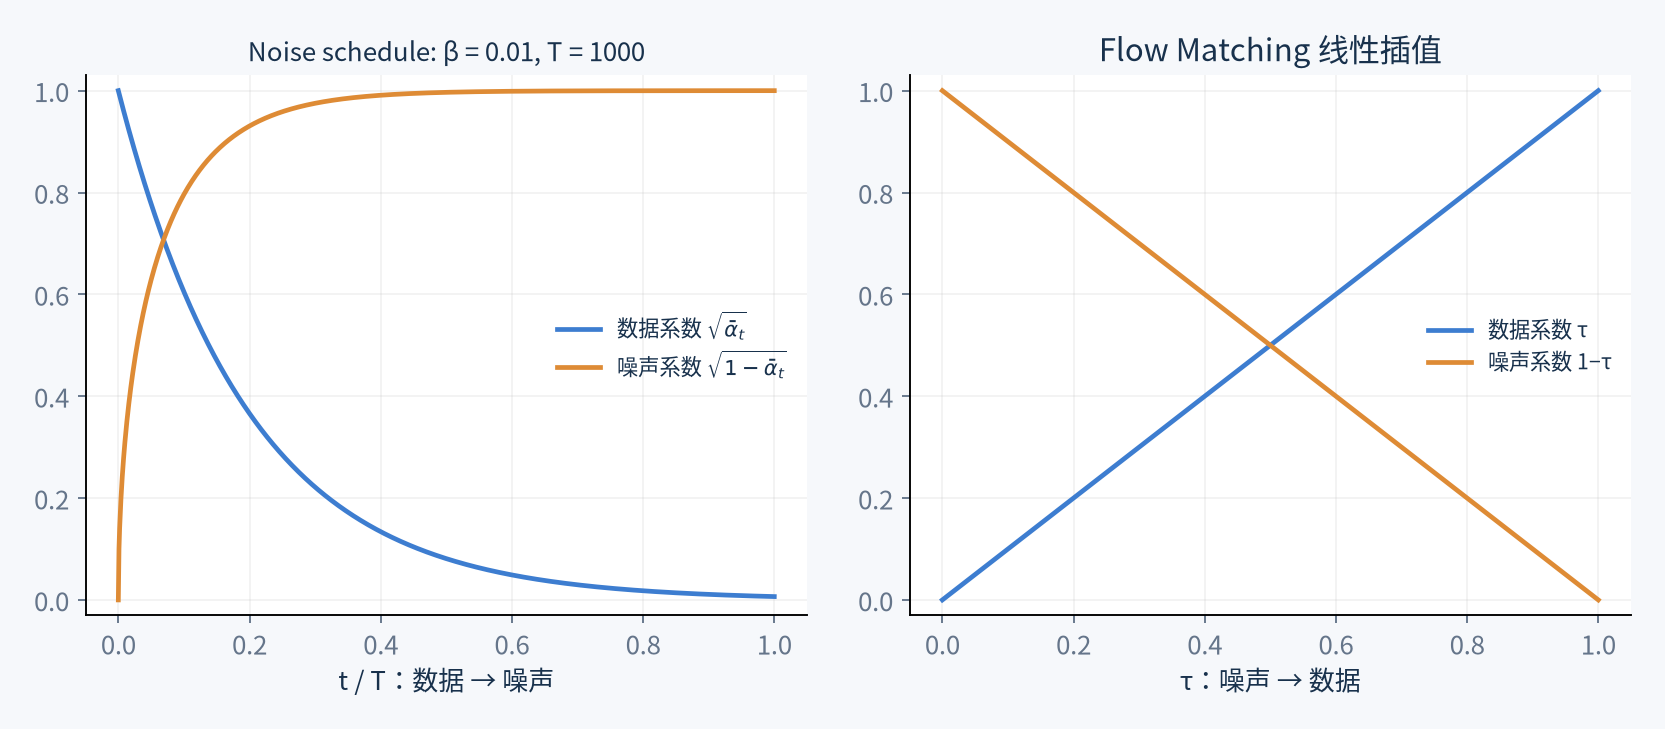

我们训练一个速度预测器：

$$
\mathcal L_{\mathrm{FM}}
=\mathbb E_{\tau,x_0,\epsilon}
\left\|v_\theta(x_\tau,\tau)-(x_0-\epsilon)\right\|^2.
$$

训练目标由这对端点直接产生，基本训练过程不需要先运行一遍 ODE。生成时则从新噪声开始积分：

$$
\frac{dx}{d\tau}=v_\theta(x,\tau),\qquad
x_{\tau+\Delta\tau}\approx x_\tau+\Delta\tau\,v_\theta(x_\tau,\tau).
$$

网络输出从噪声估计换成速度，数据扰动路径也从前面的高斯扩散路径换成这里的线性插值。不能把原 DDPM checkpoint 的输出直接解释为这个速度。


### 7.2 随机配对的直线路径，为什么能学出分布输送？

很多数据与噪声配对可能经过相同位置 $x_\tau$，网络不会知道训练时究竟抽到了哪一对。平方损失最优解仍是条件期望：

$$
v^*(x,\tau)=\mathbb E[x_0-\epsilon\mid x_\tau=x].
$$

这个平均速度为何有用，可以从任意光滑测试函数 $\phi$ 看出：

$$
\frac{d}{d\tau}\mathbb E[\phi(x_\tau)]
=\mathbb E[\nabla\phi(x_\tau)\cdot(x_0-\epsilon)]
=\mathbb E[\nabla\phi(x_\tau)\cdot v^*(x_\tau,\tau)].
$$

在适当正则条件下，这对应连续性方程
$\partial_\tau p_\tau=-\nabla\cdot(p_\tau v^*)$。
也就是说，条件回归得到的速度场能描述目标边缘分布怎样随时间变化。它不需要网络记住每一对独立端点的身份。

这也给出了边界：**每对端点之间的训练插值是直线，不等于学到的 ODE 轨迹必然都是直线。** 不同配对的速度会在条件平均中混合；数值积分时网络又在新的位置重新计算方向。[Flow Matching](https://arxiv.org/abs/2210.02747) [Rectified Flow](https://arxiv.org/abs/2209.03003)


### 7.3 Flow Matching 与 Rectified Flow 分别强调什么？

Flow Matching 是训练连续归一化流的一般框架，可以选择不同的概率路径，包括 diffusion 路径和其他输送路径。上面的线性插值是便于实现的一个具体选择，不代表整个框架只允许直线。

Rectified Flow 研究通过端点插值回归来学习流，以及进一步的 rectification/reflow：先用已有流产生新的端点耦合，再用新配对训练，促使后续轨迹变得更直、更适合粗步求解。**Reflow 是额外过程**，不是给任意一次线性插值训练换一个名称。两条工作的预印本分别出现在 2022 年 9 月、10 月，均发表于 ICLR 2023。[Rectified Flow](https://arxiv.org/abs/2209.03003) [Flow Matching](https://arxiv.org/abs/2210.02747)

Diffusion 的 probability-flow ODE 与 Flow Matching 都可以从向量场和分布演化理解；它们有联系，也有路径、监督目标和训练权重上的具体差别。将参数名称从 $\epsilon$ 改成 $v$，并不足以完整描述这些变化。


### 7.4 复用 MNIST 网络，重新训练速度预测器

下面只替换核心损失与采样循环。导入 `torch` 和 `torch.nn.functional as F`，复用第二章的 `TinyUNet` 和前面的数据加载代码：


In [ ]:
def flow_loss(model, x0, T=200):
    tau = torch.rand(len(x0), device=x0.device)
    w = tau[:, None, None, None]
    noise = torch.randn_like(x0)
    x_tau = (1 - w) * noise + w * x0
    target_velocity = x0 - noise
    return F.mse_loss(model(x_tau, tau * T), target_velocity)

@torch.no_grad()
def sample_flow(model, initial_noise, steps=50, T=200):
    x = initial_noise.clone()
    for k in range(steps):
        tau = torch.full((len(x),), k / steps, device=x.device)
        x = x + model(x, tau * T) / steps
    return x


创建一个新的网络与优化器，在训练循环中用 `flow_loss(model,x0)`。训练完成、调用 `model.eval()` 后，用 `sample_flow(model,xT)` 从高斯噪声生成。这里把 $\tau$ 乘以 200，只是让已有的时间 embedding 接口使用相似的数值范围；目标仍然是对 $\tau$ 的速度，Euler 更新不需要再乘一个 200。


In [ ]:
RUN_FLOW = False
if RUN_FLOW:
    velocity_model = TinyUNet().to(device)
    optimizer = torch.optim.AdamW(velocity_model.parameters(), lr=2e-4, weight_decay=0)
    for _ in range(10):
        velocity_model.train()
        for images, _ in loader:
            loss = flow_loss(velocity_model, images.to(device), T=200)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
    velocity_model.eval()
    samples = sample_flow(velocity_model, xT, steps=50, T=200)
    save_image((samples.clamp(-1, 1) + 1) / 2, out / "flow-samples.png", nrow=4)


训练与采样必须使用相同的时间编码约定。SD3 论文采用与本节相反的方向：数据在 0、噪声在 1，目标为 $\epsilon-x_0$，生成时向较小时间积分。两种写法都可以；端点方向、速度符号和积分步长必须一致。

更直的轨迹可能更适合少步积分，但生成质量还受模型误差、路径、训练权重和求解器影响。Flow Matching 本身不保证任意模型都可以一步生成，少步结果需要看具体训练、reflow 或蒸馏方法。


## 8．SD3 与 FLUX.1：现代生成模型怎样组合这些设计？


### 8.1 SD3：目标、条件交互与训练分布一起改变

Stable Diffusion 3 于 2024 年公开，其技术论文讨论了大规模 rectified-flow Transformer 的训练。它不是只给早期 Stable Diffusion 的 U-Net 换一个名字，而是组合了几项不同层面的变化：[SD3](https://arxiv.org/abs/2403.03206)

| 层面 | SD3 中的代表性变化 | 要解决的问题 |
| --- | --- | --- |
| 生成目标与路径 | latent 上的 rectified-flow 速度回归 | 如何学习可扩展的连续生成过程 |
| 训练时间采样 | 探索 logit-normal 等 timestep 分布 | 如何分配不同噪声区间的训练关注度 |
| 网络骨干 | MMDiT，图像和文本有各自的参数与表示 | 如何加强跨模态信息交互 |
| 表示与条件 | 改进自编码器与多种文本编码器组合 | 如何保留视觉细节并表达复杂提示 |

MMDiT 在 attention 中让文本与图像 token 交互，同时保留两种模态各自的处理参数。它与早期 U-Net 中“图像 query 读取文本 key/value”的常见 cross-attention 组织不同：联合 attention 支持两个方向的信息交互。模型结构图中出现两条流，描述的是模态处理，不是两条 diffusion 时间轴。

论文采用多种文本表示，并研究生成规模与质量。报告的成果包括文本遵循、拼写/排版及人工偏好的改进；这些结果属于其模型、数据和评测协议。不能把成果全部归因于单独一个 MMDiT block，或认为换成 velocity loss 就能复现。

另一个容易混淆的细节是“采样”：训练时从 logit-normal 分布抽取时间点，决定损失在哪些位置被计算；推理时的时间网格和 ODE solver，决定生成如何积分。它们都是对时间的选择，但作用于不同阶段。


### 8.2 FLUX.1：从公开实现看模型组合

FLUX.1 于 2024 年 8 月发布。公开模型采用 rectified-flow Transformer；官方代码先处理图像与文本双流 blocks，再将序列拼接进入单流 blocks，并使用位置与时间等条件。可从这些公开模块理解架构组织，不需要假设能够从推理代码恢复全部未公开训练细节。[发布说明](https://bfl.ai/blog/24-08-01-bfl) [固定模型实现](https://github.com/black-forest-labs/flux/blob/802fb4713906133fcbd0d8dc5351620ca4773036/src/flux/model.py)

官方采样代码将 latent 的 $2\times2$ 局部块打包成序列元素，并用类似
$x_{\mathrm{next}}=x+(t_{\mathrm{next}}-t_{\mathrm{current}})\,v_\theta$
的 Euler 更新推进。具体时间方向和模型输出约定必须一起读取；看到乘上一个负步长，不意味着实现把速度公式写错。[固定采样实现](https://github.com/black-forest-labs/flux/blob/802fb4713906133fcbd0d8dc5351620ca4773036/src/flux/sampling.py)

更值得读者掌握的是区分具体变体：

| 公开变体 | 官方说明的关键机制 | 不应混淆的结论 |
| --- | --- | --- |
| FLUX.1-dev | 12B rectified-flow Transformer，使用 guidance distillation | guidance 输入不等于普通 CFG 必须做的条件/无条件双预测 |
| FLUX.1-schnell | 使用 latent adversarial diffusion distillation，支持 1–4 步生成 | 少步能力属于该蒸馏变体，不是所有 flow 模型的自动能力 |

dev 官方示例的 50 步是一个用法设置，不是所有输入都必须使用的最优常数；schnell 的 1–4 步也不能直接代替 dev 的设置。公开 dev/schnell 的代码不能证明未公开 pro 内部每一处实现相同。[dev 模型卡](https://huggingface.co/black-forest-labs/FLUX.1-dev) [schnell 模型卡](https://huggingface.co/black-forest-labs/FLUX.1-schnell)


### 8.3 怎样分析“新模型更快了”？

如果某模型生成只需 4 步，至少可能涉及训练路径、数值求解器、蒸馏和模型本身的计算量。减少步数可能降低网络调用次数；增加模型规模、latent token 数或 guidance 分支，又可能增加每次调用的成本。

因此，对一个新模型应分别查：它在哪个空间生成、网络预测什么、用什么主干、每次调用消费什么条件、执行多少次模型，以及是否有蒸馏。技术发展带来的贡献往往是这些维度的组合，而不是某个新名字能够自动解释全部成果。


## 9．把发展脉络整理成一张技术地图


### 9.1 简明时间线

下表按预印本首次出现时间或明确发布事件记录；同一年中的路线可以并行发展，不能从表格相邻位置推断后一项继承并取代前一项。

| 时间 | 代表工作 | 主要做了什么 | 本文如何使用它 |
| --- | --- | --- | --- |
| 2015-03 | 扩散生成模型起源 | 正向逐步加噪，学习反向生成 | 理解总体构想 |
| 2019-07 | NCSN | 多噪声尺度 score 学习与采样 | 理解分布梯度视角 |
| 2020-06 | DDPM | 噪声预测与简化训练带来高质量图像生成 | 完整实验与主要推导 |
| 2020-10 | DDIM | 复用预测器，改变采样过程并跳步 | 学会区分训练和采样 |
| 2020-11 / 2021 | Score SDE | 统一连续时间描述，联系 SDE 与 ODE | 为向量场方法建立桥梁 |
| 2021 / 2022 | CFG | 条件丢弃训练与引导组合 | 从无条件数字生成扩展到指定数字 |
| 2021-12 / 2022 | LDM / Stable Diffusion v1 | 潜空间、条件输入与完整文生图系统 | 理解表示与组件分工 |
| 2022-09、10 | Rectified Flow / Flow Matching | 输送路径与速度回归 | 理解新的训练和积分组织 |
| 2022-12 / 2023 | DiT | Transformer 去噪骨干及规模研究 | 理解网络架构这一维度 |
| 2024-03 | SD3 论文 | rectified flow、MMDiT 与训练设计组合 | 综合分析一个现代系统 |
| 2024-08 | FLUX.1 | flow Transformer 与变体相关蒸馏 | 用公开实现核对设计与能力 |

CFG 的 2021 指 workshop 短版，完整 arXiv 稿在 2022；LDM 预印本与 Stable Diffusion 的公开发布也是不同事件。正文按理解依赖讲解这些工作，因此先建立 DDPM 实验，再回看与之相连的 score 路线。


### 9.2 代表模型改变的是哪个维度？

| 代表 | 生成空间 | 主要预测/训练形式 | 骨干或系统特点 |
| --- | --- | --- | --- |
| 本文均值模型 | $28\times28$ 灰度像素 | 变分目标中的均值回归 | 时间条件全连接网络 |
| 本文 MNIST DDPM | $28\times28$ 灰度像素 | 噪声 MSE | 小型时间条件 U-Net |
| Stable Diffusion v1 | 自编码器 latent | 噪声预测 | U-Net、CLIP、cross-attention、CFG |
| 原始 DiT | 自编码器 latent | diffusion 训练 | latent patch Transformer、时间/类别调制 |
| SD3 | 自编码器 latent | rectified-flow 速度回归 | MMDiT、文本条件与 training timestep sampling |
| FLUX.1-dev / schnell | 自编码器 latent | rectified flow 与各自的蒸馏 | 双流/单流 Transformer，变体能力不同 |

当阅读新论文时，可以沿五个问题推进：

1. **随机变量是什么？** 是像素、latent、视频表示，还是动作向量？
2. **网络预测什么？** 噪声、干净数据、score、速度，还是经过蒸馏的映射？
3. **训练监督怎样构造？** 时间分布、扰动/插值路径、目标与权重是什么？
4. **采样怎样使用网络？** 时间方向、求解器、步数、随机项和 guidance 如何组合？
5. **改进证据覆盖什么？** 数据、模型规模、采样成本与质量指标是否匹配？


### 9.3 练习：通过改一个变量检查理解

**练习一：检查加噪终点。** 比较本章 1000 步固定 noise schedule与 200 步、从 $10^{-4}$ 到 0.02 的线性 $\beta_t$。计算 $\bar\alpha_T$ 并画终点图片。它是否还含有明显原图信息？为什么这会影响从标准高斯开始采样的假设？

**练习二：固定模型，只改采样。** 对同一个 checkpoint 和初始噪声，分别使用 1000 步 DDPM、50 步 DDIM、20 步 DDIM。记录模型调用次数、时间和生成样本；解释为什么结果不同不代表训练模型被替换。

**练习三：检验 CFG 的约定。** 训练条件网络后，将 $s$ 分别设为 0、1、3。解释三个设置的计算含义，再观察指定数字的符合程度和多样性。不要把“更像指定数字”直接等同于“整体分布更好”。

**练习四：核对 Flow Matching 的方向。** 把线性插值改写成数据在 0、噪声在 1。同步写出正确目标和积分步长；仅交换端点而不改速度符号，会发生什么？

**练习五：分别改变表示和骨干。** 说明“像素 U-Net 换成 latent U-Net”与“latent U-Net 换成 DiT”各改变什么。哪些模块需要重新训练，哪些采样器思想仍可能复用？


## 参考资料与实验说明

日期、原始公式和模型事实以以下论文及官方实现为依据。代码为本文编写的教学实现，不声称完整复现原论文的网络规模、训练配方或指标。生成图来自本地实验，现代大模型未在本文环境重新训练或评测。

- 起源与 DDPM：[2015 原始论文](https://arxiv.org/abs/1503.03585)、[DDPM](https://arxiv.org/abs/2006.11239)、[Improved DDPM](https://arxiv.org/abs/2102.09672)。
- 连续时间与采样：[NCSN](https://arxiv.org/abs/1907.05600)、[Score SDE](https://arxiv.org/abs/2011.13456)、[DDIM](https://arxiv.org/abs/2010.02502)。
- 条件与潜空间：[CFG](https://arxiv.org/abs/2207.12598)、[Latent Diffusion](https://arxiv.org/abs/2112.10752)、[Stable Diffusion v1 官方实现](https://github.com/CompVis/stable-diffusion/blob/21f890f9da3cfbeaba8e2ac3c425ee9e998d5229/README.md)。
- Transformer 与流：[DiT](https://arxiv.org/abs/2212.09748)、[Flow Matching](https://arxiv.org/abs/2210.02747)、[Rectified Flow](https://arxiv.org/abs/2209.03003)、[SD3](https://arxiv.org/abs/2403.03206)、[FLUX.1 官方发布](https://bfl.ai/blog/24-08-01-bfl)。
- 基础实验：[torchvision MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)、[PyTorch 安装说明](https://pytorch.org/get-started/locally/)。

实验说明：第一章图片来自固定 noise schedule、固定方差的均值模型；它们不复用旧版 DDPM 的生成结果。数值公式与代码在 PyTorch 2.14 上核对，图像由 Matplotlib 绘制。GPU 与现代大模型的性能不在本实验评测范围内。

如果希望把这里的算法知识连接到服务系统，可继续读 [vLLM-Omni Diffusion Runtime](vllm-omni/vllm-omni-diffusion-runtime.md)：本文的数值采样步骤，与框架里决定请求何时进入执行的服务调度，是需要分别理解的两个层面。
